# Algebra / UltraChat：SFT 前后 loss 变化的预实验

**Run：** `math-algebra-ultrachat-lengthonly-qwen25-1p5b-seed42`  
**原始结果时间（UTC）：** 2026-10-22T11:37:52.040489+00:00  
**模型：** `Qwen/Qwen2.5-1.5B-Instruct`；主报告 checkpoint：step 32。

A2=Algebra、C=UltraChat 200k test_sft 首轮问答，各 512 条。两项指标并列考察，不设主次：loss 下降量 ROC-AUC **0.9857**（95% CI 0.9784–0.9921）；相对下降比例 ROC-AUC **0.9869**（95% CI 0.9795–0.9929）。
复用已完成的 A1-SFT 和两个模型的逐样本评分；指标、对照和局限按原预实验的结构展示。

已保存执行输出，直接打开即可查看表格和图。重跑只读取同目录的 `snapshot/`，
不需要 GPU、checkpoint 或原始数据挂载，也不会重新训练模型。
本次长度控制仅用 A2 与 UltraChat 重新分桶和匹配，更新日期记录在 manifest 中；目录时间保持不变。

## 1. 问题与评价约定

只在 A1 上做 SFT；A2 是未参与这次 SFT 的 Algebra 样本，C 是 UltraChat 通用问答。
两个模型使用完全相同的 token IDs 和回答 mask，只计算回答正文的平均 token NLL（nats/token）。
A2 为正类，所有排序方向预先固定；A1 只用于训练，不参与 A2/C 分类评价。

下降量和相对下降比例并列考察，不设主次。

- loss 下降量：`delta_loss = L_ref - L_sft`。
- 相对下降比例：`relative_gain = (L_ref - L_sft) / max(L_ref, 1e-6)`。
- 基线：`-L_ref`、`-L_sft`，即 loss 低的样本优先；反向基线在附录单列。
- 95% 区间来自 2,000 次按 domain 分层、按问题组重采样的 bootstrap。
  本 notebook 重算 AUC 和 top-k 点估计并与快照核对，区间来自保存的统计结果。

这是**同域识别**预实验，不直接检验被选数据用于后续训练时的实际收益。

In [1]:
import hashlib
import json
import math
import os
import tempfile
from pathlib import Path
if 'MPLCONFIGDIR' not in os.environ:
    scratch = Path('/dev/shm/data-picking-runtime') if Path('/dev/shm').is_dir() else Path(tempfile.gettempdir())/'data-picking-runtime'
    os.environ['MPLCONFIGDIR'] = str(scratch/'matplotlib')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.metrics import roc_auc_score, roc_curve
%matplotlib inline
plt.rcParams.update({'figure.dpi':120,'font.size':10,'axes.spines.top':False,'axes.spines.right':False})
pd.set_option('display.max_colwidth',100)

In [2]:
DIRECTORY = '2026-10-22_113752Z_math-algebra-ultrachat-lengthonly-qwen25-1p5b-seed42'

HERE = next((p for p in [Path.cwd(),Path.cwd()/'experiments-analysis'/DIRECTORY]
             if (p/'snapshot').is_dir() and (p/'manifest.json').is_file()),None)
if HERE is None: raise FileNotFoundError('请使用当前实验目录或仓库根目录作为工作目录。')
SNAPSHOT = HERE/'snapshot'
manifest = json.loads((HERE/'manifest.json').read_text())
for name,info in manifest['files'].items():
    content = (SNAPSHOT/name).read_bytes()
    assert len(content)==info['bytes'] and hashlib.sha256(content).hexdigest()==info['sha256'],name
def load_json(name): return json.loads((SNAPSHOT/name).read_text())
metrics = load_json('metrics.json')
effective = load_json('effective_config.json')
completed = load_json('training_complete.json')
extension = load_json('extension_config.json')
data_summary = load_json('data_summary.json')
duplicates = load_json('duplicate_report.json')
evaluation = pd.read_parquet(SNAPSHOT/'per_example.parquet')
training = pd.read_json(SNAPSHOT/'train.jsonl',lines=True)
matched_ids = load_json('length_matched_ids.json')
assert evaluation['id'].is_unique
assert evaluation.groupby('domain').size().to_dict()=={'A':512,'C':512}
assert set(evaluation['split'])=={'A2','C'}
assert len(set(matched_ids))==len(matched_ids) and set(matched_ids)<=set(evaluation['id'])
matched = evaluation.set_index('id').loc[matched_ids].reset_index()
assert completed['global_step']==metrics['checkpoint_step'] and metrics['primary_checkpoint']
c_manifest = pd.read_json(SNAPSHOT/'c_manifest.jsonl',lines=True)
selected_c = c_manifest.loc[c_manifest['selected']].set_index('id').sort_index()
assert len(selected_c)==512 and selected_c['sequence_tokens'].le(2048).all()
assert selected_c['response_tokens'].gt(0).all() and selected_c['exclusion_reason'].isna().all()
pd.testing.assert_series_equal(selected_c['tokenization_hash'],
    evaluation.loc[evaluation['domain']=='C'].set_index('id').sort_index()['tokenization_hash'])
print(f'快照检查通过：A2/C 配对记录 {len(evaluation)} 条，长度匹配 {len(matched)} 条。')

快照检查通过：A2/C 配对记录 1024 条，长度匹配 252 条。


## 2. 实验设置与数据划分

In [3]:
cfg = effective['config']
settings = [
    ('模型',cfg['model']['name']),('模型 revision',cfg['model']['revision']),
    ('A 数据源 / 子集',f"{cfg['data']['name']} / {cfg['data']['a_subset']}"),
    ('A 数据 revision',cfg['data']['revision']),
    ('C 数据源 / 子集',f"{extension['c_data']['name']} / {extension['c_data'].get('category',extension['c_data'].get('split'))}"),
    ('C 数据 revision',extension['c_data']['revision']),
    ('A 划分 / C 抽样 / 训练 seed',f"{cfg['data']['split_seed']} / {extension['c_data']['seed']} / {cfg['training']['seed']}"),
    ('训练规模',f"{effective['actual_train_size']} examples; {completed['seen_response_tokens']:,} response tokens"),
    ('训练长度',f"{cfg['training']['epochs']} epoch; {completed['global_step']} optimizer steps"),
    ('有效 batch / 学习率',f"{cfg['training']['effective_batch_size']} / {cfg['training']['learning_rate']}"),
    ('训练精度 / attention',f"{cfg['training']['parameter_dtype']} parameters + {cfg['training']['autocast_dtype']} autocast / {cfg['training']['attention_backend']}"),
    ('打分精度 / 主报告 checkpoint',f"float32 / step {completed['global_step']}"),
]
display(pd.DataFrame(settings,columns=['设置','值']))
display(evaluation.groupby('split').agg(条数=('id','size'),问题组=('group_id','nunique'),
    回答tokens=('response_tokens','sum'),平均prompt长度=('prompt_tokens','mean'),
    平均回答长度=('response_tokens','mean')).round(2))
display(pd.DataFrame([{'UltraChat 状态':k,'条数':v} for k,v in data_summary['status_counts'].items()]))
print('C 同题不同答组数：',duplicates['selected']['same_question_different_answer_groups'])
print('C 与原固定数据的规范化问题重合条数：',len(duplicates['selected_overlap_ids']))
if metrics['overlap_sensitivity']['excluded_c_ids']:
    display(metrics['overlap_sensitivity'])

,设置,值
0,模型,Qwen/Qwen2.5-1.5B-Instruct
1,模型 revision,989aa7980e4cf806f80c7fef2b1adb7bc71aa306
2,A 数据源 / 子集,EleutherAI/hendrycks_math / algebra
3,A 数据 revision,21a5633873b6a120296cce3e2df9d5550074f4a3
4,C 数据源 / 子集,HuggingFaceH4/ultrachat_200k / test_sft
5,C 数据 revision,8049631c405ae6576f93f445c6b8166f76f5505a
6,A 划分 / C 抽样 / 训练 seed,2026 / 20261022 / 42
7,训练规模,"1024 examples; 138,236 response tokens"
8,训练长度,1 epoch; 32 optimizer steps
9,有效 batch / 学习率,32 / 2e-05


,条数,问题组,回答tokens,平均prompt长度,平均回答长度
split,,,,,
A2,512,512,70771,72.11,138.22
C,512,512,182882,167.61,357.19


,UltraChat 状态,条数
0,eligible,22574
1,selected,512
2,overlong,22
3,empty_response,2


C 同题不同答组数： 0
C 与原固定数据的规范化问题重合条数： 0


C 使用 `HuggingFaceH4/ultrachat_200k` 的 `test_sft`：每段对话只取首轮完整 user/assistant 问答，
以保持单轮问答的评分口径。后续轮次不拼接、不作为替补答案。
从 23,086 条有效首轮问答中以固定 seed 均匀随机抽 512 条。
仅排除完整聊天模板序列超过 2,048 tokens、空内容、缺少有效首轮或无法评分的样本；
不截断答案、不设最短长度、不按数学、代码、语言或风格筛选。同题不同答保留，按规范化问题分组统计。

UltraChat 是合成对话；200k 版经过上游子集选择、大小写修正和部分拒答措辞清理。
本实验未叠加内容筛选，但结果代表这个指定版本的首轮问答，不能视为完整原始多轮分布。
来源：HuggingFaceH4；原始 UltraChat：Ding et al. (2023)。数据许可 MIT。
规范化问题匹配不能保证发现语义改写。

## 3. 训练过程与两域 loss 变化

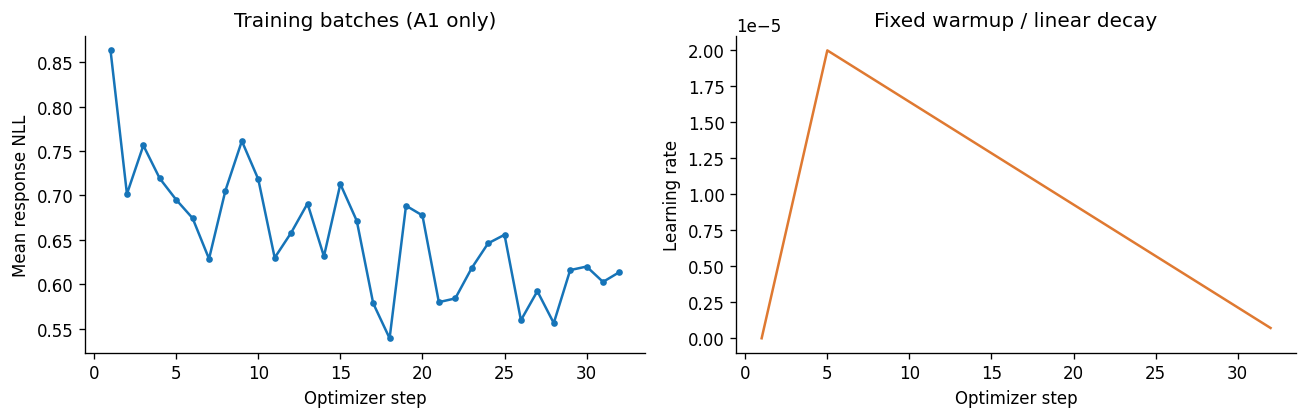

训练 step 记录的耗时合计 97.3 秒；不含模型加载、checkpoint I/O 和评分。


In [4]:
assert training['step'].tolist()==list(range(1,completed['global_step']+1))
assert np.isfinite(training[['loss','lr']].to_numpy()).all()
assert int(training['response_tokens'].sum())==completed['seen_response_tokens']
fig,axes = plt.subplots(1,2,figsize=(11,3.6))
axes[0].plot(training['step'],training['loss'],marker='.',color='#1674B8')
axes[0].set(xlabel='Optimizer step',ylabel='Mean response NLL',title='Training batches (A1 only)')
axes[1].plot(training['step'],training['lr'],color='#DF7931')
axes[1].set(xlabel='Optimizer step',ylabel='Learning rate',title='Fixed warmup / linear decay')
fig.tight_layout();plt.show();plt.close(fig)
print(f"训练 step 记录的耗时合计 {training['seconds'].sum():.1f} 秒；不含模型加载、checkpoint I/O 和评分。")

每一步的 batch 内容不同，因此训练曲线不等于固定评估集上的学习曲线。下面仅比较 A2 与 UltraChat 的相同样本在两个模型下的 loss。

,条数,ref_NLL,SFT_NLL,平均下降量,loss 下降样本比例
split,,,,,
A2,512,0.8093,0.6374,0.1719,0.9746
C,512,1.0994,1.1654,-0.0660,0.0625


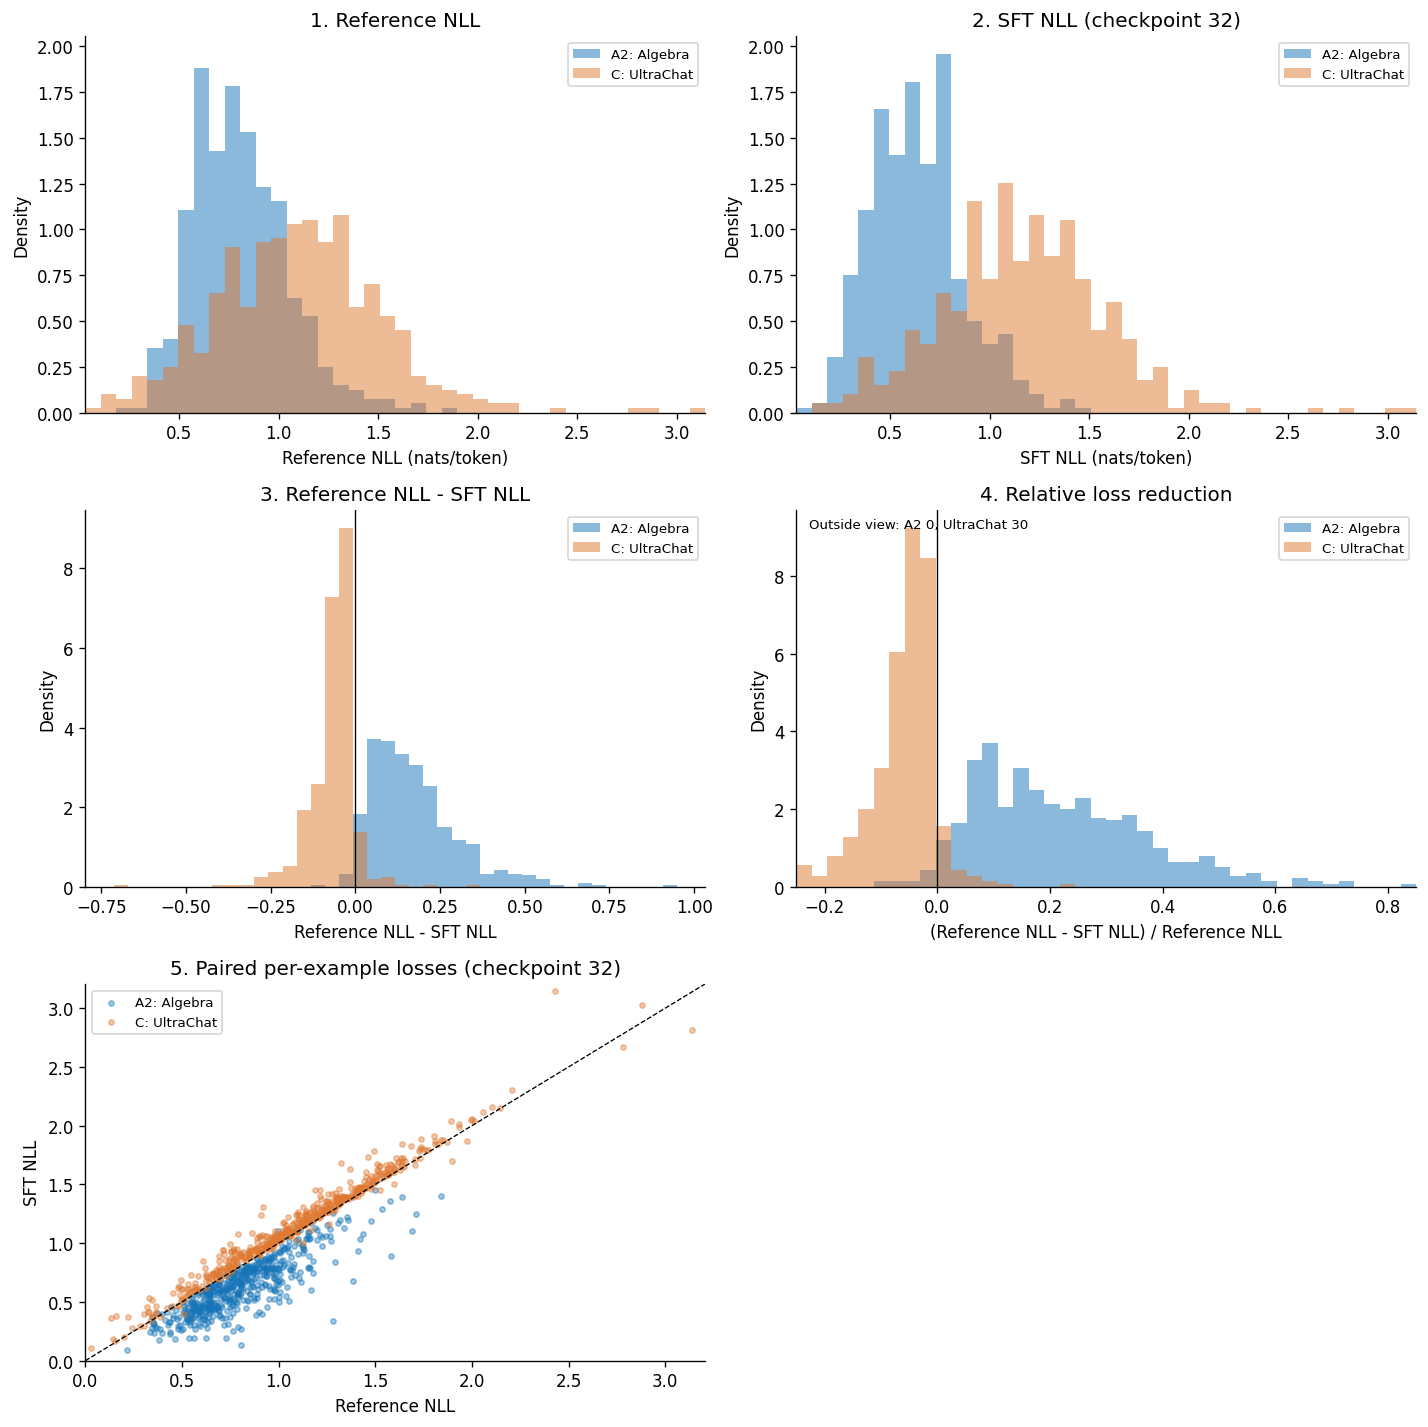

相对下降比例主图显示 [-0.25, 0.85]，均匀分为 40 桶；密度按每域全部样本归一化。
范围外样本如下，仍全部参与 AUC、top-k 等统计计算：


,id,split,ref_mean_nll,sft_mean_nll,relative_gain,response_tokens
514,ultrachat:test_sft:10118,C,0.910898,1.243442,-0.365073,44
523,ultrachat:test_sft:10428,C,0.790837,1.074888,-0.359179,86
529,ultrachat:test_sft:10702,C,0.328744,0.532297,-0.619184,67
535,ultrachat:test_sft:11043,C,0.920219,1.311252,-0.424935,81
538,ultrachat:test_sft:11125,C,0.862710,1.090721,-0.264295,20
566,ultrachat:test_sft:11758,C,0.135209,0.359557,-1.659274,24
581,ultrachat:test_sft:12222,C,0.495221,0.689032,-0.391361,119
615,ultrachat:test_sft:13568,C,0.028622,0.108023,-2.774109,28
618,ultrachat:test_sft:13704,C,0.607937,0.845670,-0.391049,142
630,ultrachat:test_sft:1427,C,0.344361,0.517669,-0.503277,165


In [5]:
loss_table = evaluation.groupby('split').agg(条数=('id','size'),ref_NLL=('ref_mean_nll','mean'),
    SFT_NLL=('sft_mean_nll','mean'),平均下降量=('delta_loss','mean'))
loss_table['loss 下降样本比例'] = evaluation.groupby('split')['delta_loss'].apply(lambda x:(x>0).mean())
display(loss_table.round(4))
colors = {'A':'#1674B8','C':'#DF7931'}
domain_names = {'A':'A2: Algebra','C':'C: UltraChat'}
scoring_steps = evaluation['checkpoint_step'].unique()
assert len(scoring_steps)==1
sft_step = int(scoring_steps[0]);assert sft_step==completed['global_step']
fig = plt.figure(figsize=(12,12))
grid = fig.add_gridspec(3,2)
axes = [fig.add_subplot(grid[row,col]) for row in range(2) for col in range(2)]
axes.append(fig.add_subplot(grid[2,0]))
nll_bins = np.histogram_bin_edges(evaluation[['ref_mean_nll','sft_mean_nll']].to_numpy().ravel(),bins=40)
relative_limits = (-0.25,0.85)
relative_bins = np.linspace(*relative_limits,41)
relative_outliers = evaluation.loc[~evaluation['relative_gain'].between(*relative_limits)]
distributions = [
    ('ref_mean_nll','Reference NLL (nats/token)','1. Reference NLL'),
    ('sft_mean_nll','SFT NLL (nats/token)',f'2. SFT NLL (checkpoint {sft_step})'),
    ('delta_loss','Reference NLL - SFT NLL','3. Reference NLL - SFT NLL'),
    ('relative_gain','(Reference NLL - SFT NLL) / Reference NLL','4. Relative loss reduction'),
]
for ax,(column,xlabel,title) in zip(axes[:4],distributions):
    bins = (relative_bins if column=='relative_gain' else nll_bins if column in {'ref_mean_nll','sft_mean_nll'}
            else np.histogram_bin_edges(evaluation[column],bins=40))
    for domain,group in evaluation.groupby('domain'):
        if column=='relative_gain':
            # Normalize by all domain samples, including those outside the view.
            weights = np.full(len(group),1/(len(group)*(bins[1]-bins[0])))
            ax.hist(group[column],bins=bins,weights=weights,alpha=.5,label=domain_names[domain],color=colors[domain])
        else:
            ax.hist(group[column],bins=bins,density=True,alpha=.5,label=domain_names[domain],color=colors[domain])
    if column in {'delta_loss','relative_gain'}: ax.axvline(0,color='black',linewidth=.8)
    ax.set(xlabel=xlabel,ylabel='Density',title=title)
    if column=='relative_gain':
        ax.set_xlim(*relative_limits)
        counts = relative_outliers['domain'].value_counts()
        ax.text(.02,.98,f"Outside view: A2 {counts.get('A',0)}, UltraChat {counts.get('C',0)}",
                transform=ax.transAxes,ha='left',va='top',fontsize=8)
nll_ymax = max(ax.get_ylim()[1] for ax in axes[:2])
for ax in axes[:2]: ax.set(xlim=(nll_bins[0],nll_bins[-1]),ylim=(0,nll_ymax))
for domain,group in evaluation.groupby('domain'):
    axes[4].scatter(group['ref_mean_nll'],group['sft_mean_nll'],s=10,alpha=.4,label=domain_names[domain],color=colors[domain])
bound = evaluation[['ref_mean_nll','sft_mean_nll']].to_numpy().max()*1.02
axes[4].plot([0,bound],[0,bound],'k--',linewidth=.8)
axes[4].set(xlabel='Reference NLL',ylabel='SFT NLL',title=f'5. Paired per-example losses (checkpoint {sft_step})',
            xlim=(0,bound),ylim=(0,bound))
for ax in axes: ax.legend(fontsize=8)
fig.tight_layout();plt.show();plt.close(fig)
print('相对下降比例主图显示 [-0.25, 0.85]，均匀分为 40 桶；密度按每域全部样本归一化。')
print('范围外样本如下，仍全部参与 AUC、top-k 等统计计算：')
display(relative_outliers[['id','split','ref_mean_nll','sft_mean_nll','relative_gain','response_tokens']].round(6))

## 4. 能否把 A2 排在 UltraChat 前面？

In [6]:
score_keys = ['delta_loss','relative_gain','neg_ref_loss','neg_sft_loss']
score_labels = {'delta_loss':'loss 下降量','relative_gain':'相对下降比例',
                'neg_ref_loss':'ref loss，低值优先','neg_sft_loss':'SFT loss，低值优先'}
def point_metrics(frame,key,ties):
    y = (frame['domain']=='A').to_numpy(dtype=int)
    order = np.lexsort((ties,-frame[key].to_numpy()))
    return {'roc_auc':roc_auc_score(y,frame[key]),
            'precision_top_10pct':y[order[:math.ceil(len(y)*.1)]].mean(),
            'precision_top_20pct':y[order[:math.ceil(len(y)*.2)]].mean()}
for frame,stored in [(evaluation,metrics['main']),(matched,metrics['length_matched'])]:
    ties = np.random.default_rng(stored['tie_seed']).random(len(frame))
    for key in stored['scores']:
        for name,value in point_metrics(frame,key,ties).items():
            np.testing.assert_allclose(value,stored['scores'][key][name],rtol=0,atol=1e-12)
def interval(v): return f'[{v[0]:.4f}, {v[1]:.4f}]'
def metric_table(result,keys=score_keys):
    return pd.DataFrame([{'排序指标':score_labels.get(key,key),'ROC-AUC':round(result['scores'][key]['roc_auc'],4),
        'Top 10% A2':f"{result['scores'][key]['precision_top_10pct']:.1%}",
        'Top 20% A2':f"{result['scores'][key]['precision_top_20pct']:.1%}"} for key in keys]).set_index('排序指标')
display(metric_table(metrics['main']))
print('原始池和长度匹配池的 AUC、top-k 点估计均已重新计算，并与快照一致。')
print(f"原始池 top 10% 取前 {math.ceil(len(evaluation)*.1)} 条；A2/C 各占一半，随机 A2 占比期望为 50%。")

,ROC-AUC,Top 10% A2,Top 20% A2
排序指标,,,
loss 下降量,0.9857,99.0%,99.0%
相对下降比例,0.9869,100.0%,100.0%
ref loss，低值优先,0.7339,54.4%,68.8%
SFT loss，低值优先,0.8722,82.5%,85.9%


原始池和长度匹配池的 AUC、top-k 点估计均已重新计算，并与快照一致。
原始池 top 10% 取前 103 条；A2/C 各占一半，随机 A2 占比期望为 50%。


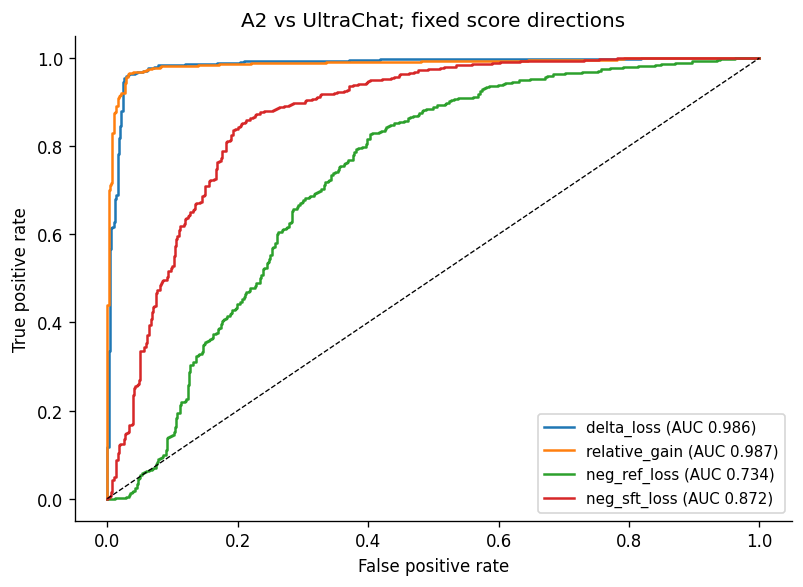

In [7]:
y = (evaluation['domain']=='A').to_numpy(dtype=int)
fig,ax = plt.subplots(figsize=(6.8,5))
for key in score_keys:
    fpr,tpr,_ = roc_curve(y,evaluation[key])
    ax.plot(fpr,tpr,label=f"{key} (AUC {metrics['main']['scores'][key]['roc_auc']:.3f})")
ax.plot([0,1],[0,1],'k--',linewidth=.8)
ax.set(xlabel='False positive rate',ylabel='True positive rate',title='A2 vs UltraChat; fixed score directions')
ax.legend(fontsize=9);fig.tight_layout();plt.show();plt.close(fig)

## 5. 长度控制及相对基线的增益

仅用 A2/C 混合池的 prompt/response 长度四分位建立联合分桶，每桶从两域各取相同数量，
未使用模型分数挑样本。下面读取保存的匹配 ID，展示同一份控制样本。
匹配改变了评估人群，且分桶不能保证完全消除长度或其他混杂因素。

In [8]:
print(f'匹配保留 {len(matched)}/{len(evaluation)} 条（{len(matched)/len(evaluation):.1%}）。')
display(pd.DataFrame({'原始池':evaluation.groupby('split').size(),'长度匹配':matched.groupby('split').size()}))
display(metric_table(metrics['length_matched']))
length_rows = []
for pool,result in [('原始池',metrics['main']),('长度匹配',metrics['length_matched'])]:
    for column,values in result['length_baselines'].items():
        length_rows.append({'评估集':pool,'长度特征':column,'+长度 AUC':values['positive_auc'],'-长度 AUC':values['negative_auc']})
display(pd.DataFrame(length_rows).round(4))

匹配保留 252/1024 条（24.6%）。


,原始池,长度匹配
split,,
A2,512,126
C,512,126


,ROC-AUC,Top 10% A2,Top 20% A2
排序指标,,,
loss 下降量,0.9727,100.0%,100.0%
相对下降比例,0.9722,100.0%,100.0%
ref loss，低值优先,0.7654,61.5%,66.7%
SFT loss，低值优先,0.8795,88.5%,88.2%


,评估集,长度特征,+长度 AUC,-长度 AUC
0,原始池,prompt_tokens,0.2862,0.7138
1,原始池,response_tokens,0.2247,0.7753
2,长度匹配,prompt_tokens,0.4887,0.5113
3,长度匹配,response_tokens,0.4768,0.5232


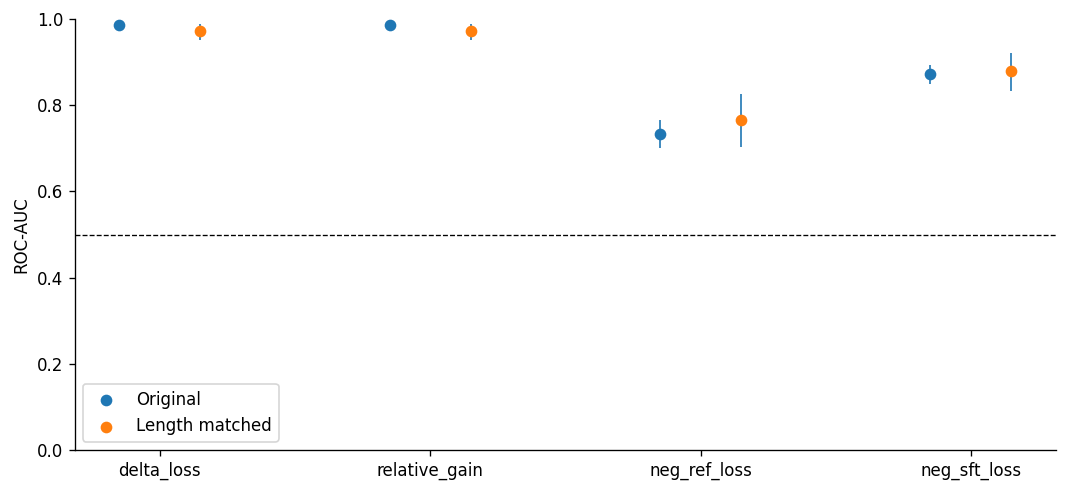

,评估集,比较,AUC 差,配对 95% CI,区间覆盖 0
0,原始池,delta_loss − neg_ref_loss,0.2517,"[0.2194, 0.2853]",False
1,原始池,delta_loss − neg_sft_loss,0.1135,"[0.0911, 0.1380]",False
2,长度匹配,delta_loss − neg_ref_loss,0.2073,"[0.1434, 0.2734]",False
3,长度匹配,delta_loss − neg_sft_loss,0.0932,"[0.0492, 0.1419]",False


In [9]:
fig,ax = plt.subplots(figsize=(9,4.2))
for shift,pool,result in [(-.15,'Original',metrics['main']),(.15,'Length matched',metrics['length_matched'])]:
    positions = np.arange(len(score_keys))+shift
    ax.scatter(positions,[result['scores'][k]['roc_auc'] for k in score_keys],label=pool,zorder=3)
    for position,key in zip(positions,score_keys): ax.vlines(position,*result['scores'][key]['roc_auc_ci95'],linewidth=1)
ax.axhline(.5,linestyle='--',color='black',linewidth=.8)
ax.set(xticks=np.arange(len(score_keys)),xticklabels=score_keys,ylabel='ROC-AUC',ylim=(0,1))
ax.legend();fig.tight_layout();plt.show();plt.close(fig)
comparisons = []
for pool,result in [('原始池',metrics['main']),('长度匹配',metrics['length_matched'])]:
    for baseline in ['neg_ref_loss','neg_sft_loss']:
        value = result['paired_delta_auc_minus_baseline'][baseline]
        lo,hi = value['ci95']
        comparisons.append({'评估集':pool,'比较':'delta_loss − '+baseline,'AUC 差':round(value['difference'],4),
                            '配对 95% CI':interval(value['ci95']),'区间覆盖 0':lo<=0<=hi})
display(pd.DataFrame(comparisons))

## 6. 结论与边界

In [10]:
texts = []
for key in ['delta_loss', 'relative_gain']:
    value = metrics['main']['scores'][key]
    lo, hi = value['roc_auc_ci95']
    signal = ('在固定方向上有区分信号' if lo > .5 else
              '区分方向与预设假设相反，没有事后翻转分数' if hi < .5 else
              '区间覆盖 0.5，尚无稳定的区分证据')
    texts.append(f"{score_labels[key]}：AUC {value['roc_auc']:.4f}，95% CI {interval(value['roc_auc_ci95'])}；{signal}。")
a2,c = metrics['loss_summary']['A2'],metrics['loss_summary']['C']
texts.append(f"A2 平均 NLL：{a2['ref_mean_nll']['mean']:.4f} → {a2['sft_mean_nll']['mean']:.4f}；"
                f"UltraChat：{c['ref_mean_nll']['mean']:.4f} → {c['sft_mean_nll']['mean']:.4f}。")
if a2['delta_loss']['mean']>0 and c['delta_loss']['mean']>0:
    texts.append('两个域的平均 loss 都下降，区分效果没有依赖 UltraChat 的平均 loss 恶化。')
elif a2['delta_loss']['mean']>0 and c['delta_loss']['mean']<0:
    texts.append('A2 的平均 loss 下降，而 UltraChat 的平均 loss 上升；区分效果同时包含目标域改善和这批通用问答的损失恶化。')
for key in ['delta_loss', 'relative_gain']:
    v = metrics['length_matched']['scores'][key]
    texts.append(f"长度匹配后，{score_labels[key]} AUC 为 {v['roc_auc']:.4f}，95% CI {interval(v['roc_auc_ci95'])}。")
for label,result,baseline in [('loss 下降量在原始池中与 SFT loss 比较',metrics['main'],'neg_sft_loss'),
                             ('loss 下降量在长度匹配后与 ref loss 比较',metrics['length_matched'],'neg_ref_loss')]:
    v = result['paired_delta_auc_minus_baseline'][baseline]
    lo,hi = v['ci95']
    texts.append(f'{label}：配对区间覆盖 0，额外区分收益尚不确定。' if lo<=0<=hi else
                 f"{label}：AUC 差 {v['difference']:.4f}，95% CI {interval(v['ci95'])}。")
length_auc = metrics['length_matched']['length_baselines']['prompt_tokens']['positive_auc']
texts.append(f'长度匹配保留 {len(matched)/len(evaluation):.1%} 的样本；匹配后仅凭 prompt 长度的 AUC 仍为 {length_auc:.4f}，需注意桶内剩余差异。')
best = max(score_keys,key=lambda k:metrics['main']['scores'][k]['roc_auc'])
texts.append(f'本轮 {score_labels[best]} 的 AUC 点估计最高；这不自动证明它显著优于其他指标。')
display(Markdown('\n\n'.join(texts)))

loss 下降量：AUC 0.9857，95% CI [0.9784, 0.9921]；在固定方向上有区分信号。

相对下降比例：AUC 0.9869，95% CI [0.9795, 0.9929]；在固定方向上有区分信号。

A2 平均 NLL：0.8093 → 0.6374；UltraChat：1.0994 → 1.1654。

A2 的平均 loss 下降，而 UltraChat 的平均 loss 上升；区分效果同时包含目标域改善和这批通用问答的损失恶化。

长度匹配后，loss 下降量 AUC 为 0.9727，95% CI [0.9520, 0.9895]。

长度匹配后，相对下降比例 AUC 为 0.9722，95% CI [0.9513, 0.9889]。

loss 下降量在原始池中与 SFT loss 比较：AUC 差 0.1135，95% CI [0.0911, 0.1380]。

loss 下降量在长度匹配后与 ref loss 比较：AUC 差 0.2073，95% CI [0.1434, 0.2734]。

长度匹配保留 24.6% 的样本；匹配后仅凭 prompt 长度的 AUC 仍为 0.4887，需注意桶内剩余差异。

本轮 相对下降比例 的 AUC 点估计最高；这不自动证明它显著优于其他指标。

本轮只有一个模型、一个训练 seed 和一次数据划分；bootstrap 区间不包含训练随机性。
平衡评估池上的 top-k 占比不能直接外推到其他 A2/C 比例的候选池。
UltraChat 与 MATH 的来源、题型、格式和答案质量不同，可分性不能单独解释为领域效应。

后续可做（本轮未运行）：固定方案补独立 seed/划分，再在未参与选择的 A_test 上比较
按不同分数和随机方法选数后的实际训练收益，匹配训练 token 预算。

本轮更换通用数据来源，用于检验结果对来源的敏感性。一次固定抽样并未估计多个 C 抽样 seed 或训练 seed 的方差；不能仅凭这次复验声称随机性已经消除。

## 7. 验证记录与原始产物

In [11]:
display(pd.DataFrame([
    ('保存 optimizer / 自动恢复',f"{effective['save_optimizer']} / {effective['auto_resume']}"),
    ('A2 与原评分最大 NLL 差',metrics['a2_original_max_nll_difference']),
    ('相对下降分母保护触发数',metrics['relative_gain_denominator_clamps']),
    ('长度分桶数据',metrics['length_matching']['domains']),
    ('当前统计更新时间（UTC）',metrics['updated_at_utc']),
],columns=['检查','结果']))
print('原始 run：',manifest['source_run_dir'])
print('最终 checkpoint：',completed['checkpoint'])
print('时间来源：',manifest['timestamp_basis'])
display(pd.DataFrame([{'文件':name,'bytes':info['bytes'],'SHA-256':info['sha256']}
                     for name,info in manifest['files'].items()]).set_index('文件'))

,检查,结果
0,保存 optimizer / 自动恢复,True / True
1,A2 与原评分最大 NLL 差,"{'ref': 2.384185791015625e-05, 'sft': 3.039836883544922e-06}"
2,相对下降分母保护触发数,0
3,长度分桶数据,"[A, C]"
4,当前统计更新时间（UTC）,2026-10-22T11:38:32.175482+00:00


原始 run： /mnt/tianzhu_hot/data-picking/runs/math-algebra-ultrachat-lengthonly-qwen25-1p5b-seed42
最终 checkpoint： /mnt/tianzhu_hot/data-picking/runs/math-algebra-numbertheory-qwen25-1p5b-seed42/checkpoints/step-000032-1d6e5f24
时间来源： Original extension completion time; preserved when editing the review notebook


,bytes,SHA-256
文件,,
metrics.json,15406,38103b96f269804f047e12649ec7b285cb66fd1fa4a29a4b8ff3e925004a7a95
per_example.parquet,295796,52fe9b539746fc27ee28be24fef8fc6afccd8186367818900b1d66f3cf189ba1
length_matched_ids.json,6660,09260371fb339eaa2194050abd6d7b7248b96d6c48be7fdbfbb02f793f0aadb5
effective_config.json,37891,77b1ac90935052496f3e256faf7581368cacc668a53731abcdaa5008d1326676
training_complete.json,275,e412bde65bca5db9f5d373fe911ffe428fa7fe92e1745536ea3210a6e50237bb
train.jsonl,5959,ed7d71c19a71272f636aa7f510f28718b9983d672a407ac1cef542803e9595e3
extension_config.json,1351,b67847e1edda01366bcb28f0c4327f9df96b2bc8984d28e7315dff4da2860500
data_summary.json,5084,e0a32f1f1dc1c1dc237cd5152fcadfc435c6e107bb163d0ac7a46d13fc6cf00e
duplicate_report.json,968,4b8d311c2f240b9844991a17b0922947b585a2828b4148ccaa1fb77d54ab30cf


评分使用完整 float32，因为 bf16 在不同 batch/padding 下曾出现约 0.0047 nats/token 的差异。
当前单样本评分与原 A2 批量推理采用相同 tokenization，并记录数值复核误差。
模型权重、optimizer、数据下载和 token 缓存保留在原始挂载；本目录保存便于 review 的分析快照。

## 附录：预先规定的反向原始 loss 基线

In [12]:
display(metric_table(metrics['main'],keys=['pos_ref_loss','pos_sft_loss']))

,ROC-AUC,Top 10% A2,Top 20% A2
排序指标,,,
pos_ref_loss,0.2661,8.7%,12.2%
pos_sft_loss,0.1278,0.0%,2.4%
